# AutoHelp D2 Model Training

This notebook trains machine learning models on the AutoHelp Lesotho dataset to predict successful mechanic-customer matches.

Models trained:
- Baseline (rule-based)
- Logistic Regression
- Random Forest

Dataset: AutoHelp_D1_Dataset.csv (1000 synthetic records)

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

## Load Dataset

In [2]:
# Load dataset
df = pd.read_csv('AutoHelp_D1_Dataset.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst few rows:")
df.head()

Dataset shape: (1000, 15)

Columns: ['id', 'district', 'town', 'problem_category', 'vehicle_age_band', 'specialty_match', 'mechanic_verified', 'mechanic_experience_years', 'availability_status', 'distance_km', 'historical_completion_rate', 'quoted_price_maloti', 'successful_match', 'is_synthetic', 'created_at']

First few rows:


,id,district,town,problem_category,vehicle_age_band,specialty_match,mechanic_verified,mechanic_experience_years,availability_status,distance_km,historical_completion_rate,quoted_price_maloti,successful_match,is_synthetic,created_at
0,SYN-0001,Butha-Buthe,Butha-Buthe,Electrical,8-12 years,1,1,11,unavailable,64.7,0.80,1453,0,True,2026-05-09
1,SYN-0002,Thaba-Tseka,Katse,Engine,4-7 years,0,1,10,available,15.4,0.78,2302,1,True,2025-12-01
2,SYN-0003,Leribe,Peka,Battery,4-7 years,1,1,9,available,85.5,0.77,447,1,True,2026-05-25
3,SYN-0004,Maseru,Mazenod,Engine,8-12 years,0,0,6,unavailable,18.4,0.80,815,0,True,2025-03-01
4,SYN-0005,Butha-Buthe,Oxbow,Engine,8-12 years,0,1,6,available,106.6,0.73,2790,0,True,2026-01-26


## Data Preprocessing

In [3]:
# Select features
feature_cols = ['specialty_match', 'mechanic_verified', 'mechanic_experience_years',
                'availability_status', 'distance_km', 'historical_completion_rate',
                'quoted_price_maloti', 'vehicle_age_band', 'problem_category']

# Create feature matrix
X = df[feature_cols].copy()
y = df['successful_match']

# One-hot encode categorical variables
X = pd.get_dummies(X, columns=['vehicle_age_band', 'problem_category'], drop_first=False)

# Convert availability_status to binary
X['availability_status'] = (X['availability_status'] == 'available').astype(int)

# Normalize numerical features
scaler = StandardScaler()
numerical_cols = ['mechanic_experience_years', 'distance_km', 'historical_completion_rate', 'quoted_price_maloti']
X[numerical_cols] = scaler.fit_transform(X[numerical_cols])

print(f"Feature matrix shape: {X.shape}")
print(f"\nFeatures: {X.columns.tolist()}")

Feature matrix shape: (1000, 17)

Features: ['specialty_match', 'mechanic_verified', 'mechanic_experience_years', 'availability_status', 'distance_km', 'historical_completion_rate', 'quoted_price_maloti', 'vehicle_age_band_0-3 years', 'vehicle_age_band_13+ years', 'vehicle_age_band_4-7 years', 'vehicle_age_band_8-12 years', 'problem_category_Battery', 'problem_category_Brakes', 'problem_category_Electrical', 'problem_category_Engine', 'problem_category_Other', 'problem_category_Tyre']


## Train/Test Split

In [4]:
# 80/20 stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"\nClass balance in train: {y_train.value_counts().to_dict()}")
print(f"Class balance in test: {y_test.value_counts().to_dict()}")

Training set: 800 samples
Test set: 200 samples

Class balance in train: {0: 416, 1: 384}
Class balance in test: {0: 104, 1: 96}


## Baseline Model (Rule-based)

In [5]:
def baseline_predict(X):
    """Rule-based: predict success if specialty matches AND mechanic is available"""
    predictions = []
    for _, row in X.iterrows():
        specialty_match = row.get('specialty_match', 0) == 1
        available = row.get('availability_status', 0) == 1
        predictions.append(1 if (specialty_match and available) else 0)
    return np.array(predictions)

# Train and evaluate baseline
y_pred_baseline = baseline_predict(X_test)

baseline_metrics = {
    'accuracy': accuracy_score(y_test, y_pred_baseline),
    'precision': precision_score(y_test, y_pred_baseline, zero_division=0),
    'recall': recall_score(y_test, y_pred_baseline, zero_division=0),
    'f1': f1_score(y_test, y_pred_baseline, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_pred_baseline)
}

print("Baseline Model Metrics:")
for metric, value in baseline_metrics.items():
    print(f"  {metric}: {value:.4f}")

baseline_cm = confusion_matrix(y_test, y_pred_baseline)
print(f"\nConfusion Matrix:")
print(baseline_cm)

Baseline Model Metrics:
  accuracy: 0.8050
  precision: 0.8434
  recall: 0.7292
  f1: 0.7821
  roc_auc: 0.8021

Confusion Matrix:
[[91 13]
 [26 70]]


## Logistic Regression

In [6]:
# Train Logistic Regression
lr = LogisticRegression(random_state=RANDOM_SEED, max_iter=1000)
lr.fit(X_train, y_train)

# Predict
y_pred_lr = lr.predict(X_test)
y_proba_lr = lr.predict_proba(X_test)[:, 1]

# Metrics
lr_metrics = {
    'accuracy': accuracy_score(y_test, y_pred_lr),
    'precision': precision_score(y_test, y_pred_lr, zero_division=0),
    'recall': recall_score(y_test, y_pred_lr, zero_division=0),
    'f1': f1_score(y_test, y_pred_lr, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_proba_lr)
}

print("Logistic Regression Metrics:")
for metric, value in lr_metrics.items():
    print(f"  {metric}: {value:.4f}")

lr_cm = confusion_matrix(y_test, y_pred_lr)
print(f"\nConfusion Matrix:")
print(lr_cm)

# Feature importance (coefficients)
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': lr.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print(f"\nTop 10 Feature Coefficients:")
print(feature_importance.head(10))

Logistic Regression Metrics:
  accuracy: 0.8750
  precision: 0.9080
  recall: 0.8229
  f1: 0.8634
  roc_auc: 0.9469

Confusion Matrix:
[[96  8]
 [17 79]]

Top 10 Feature Coefficients:
                        feature  coefficient
3           availability_status     4.459650
0               specialty_match     3.787980
4                   distance_km    -1.635014
1             mechanic_verified     1.538023
8    vehicle_age_band_13+ years    -0.989090
7    vehicle_age_band_0-3 years     0.578866
15       problem_category_Other    -0.541831
14      problem_category_Engine     0.408338
6           quoted_price_maloti    -0.348607
10  vehicle_age_band_8-12 years     0.320918


## Random Forest

In [7]:
# Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED, max_depth=5)
rf.fit(X_train, y_train)

# Predict
y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

# Metrics
rf_metrics = {
    'accuracy': accuracy_score(y_test, y_pred_rf),
    'precision': precision_score(y_test, y_pred_rf, zero_division=0),
    'recall': recall_score(y_test, y_pred_rf, zero_division=0),
    'f1': f1_score(y_test, y_pred_rf, zero_division=0),
    'roc_auc': roc_auc_score(y_test, y_proba_rf)
}

print("Random Forest Metrics:")
for metric, value in rf_metrics.items():
    print(f"  {metric}: {value:.4f}")

rf_cm = confusion_matrix(y_test, y_pred_rf)
print(f"\nConfusion Matrix:")
print(rf_cm)

# Feature importance
rf_feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\nTop 10 Feature Importances:")
print(rf_feature_importance.head(10))

Random Forest Metrics:
  accuracy: 0.8900
  precision: 0.9022
  recall: 0.8646
  f1: 0.8830
  roc_auc: 0.9451

Confusion Matrix:
[[95  9]
 [13 83]]

Top 10 Feature Importances:
                        feature  importance
3           availability_status    0.308200
0               specialty_match    0.264369
4                   distance_km    0.183373
5    historical_completion_rate    0.052752
6           quoted_price_maloti    0.051890
1             mechanic_verified    0.042838
2     mechanic_experience_years    0.034404
8    vehicle_age_band_13+ years    0.023615
14      problem_category_Engine    0.005360
10  vehicle_age_band_8-12 years    0.004836


## 5-Fold Cross-Validation

In [8]:
# Cross-validation for Logistic Regression
lr_cv_scores = cross_val_score(lr, X_train, y_train, cv=5, scoring='f1')
print(f"Logistic Regression 5-Fold CV F1: {lr_cv_scores}")
print(f"Mean F1: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std() * 2:.4f})")

# Cross-validation for Random Forest
rf_cv_scores = cross_val_score(rf, X_train, y_train, cv=5, scoring='f1')
print(f"\nRandom Forest 5-Fold CV F1: {rf_cv_scores}")
print(f"Mean F1: {rf_cv_scores.mean():.4f} (+/- {rf_cv_scores.std() * 2:.4f})")

Logistic Regression 5-Fold CV F1: [0.82802548 0.83783784 0.84563758 0.84415584 0.91025641]
Mean F1: 0.8532 (+/- 0.0584)



Random Forest 5-Fold CV F1: [0.81081081 0.82993197 0.77464789 0.81081081 0.83443709]
Mean F1: 0.8121 (+/- 0.0422)


## Model Comparison

In [9]:
# Compare all models
comparison = pd.DataFrame({
    'Baseline': baseline_metrics,
    'Logistic Regression': lr_metrics,
    'Random Forest': rf_metrics
}).T

print("Model Comparison (Test Set):")
print(comparison.round(4))

Model Comparison (Test Set):
                     accuracy  precision  recall      f1  roc_auc
Baseline                0.805     0.8434  0.7292  0.7821   0.8021
Logistic Regression     0.875     0.9080  0.8229  0.8634   0.9469
Random Forest           0.890     0.9022  0.8646  0.8830   0.9451


## Confusion Matrix Visualization

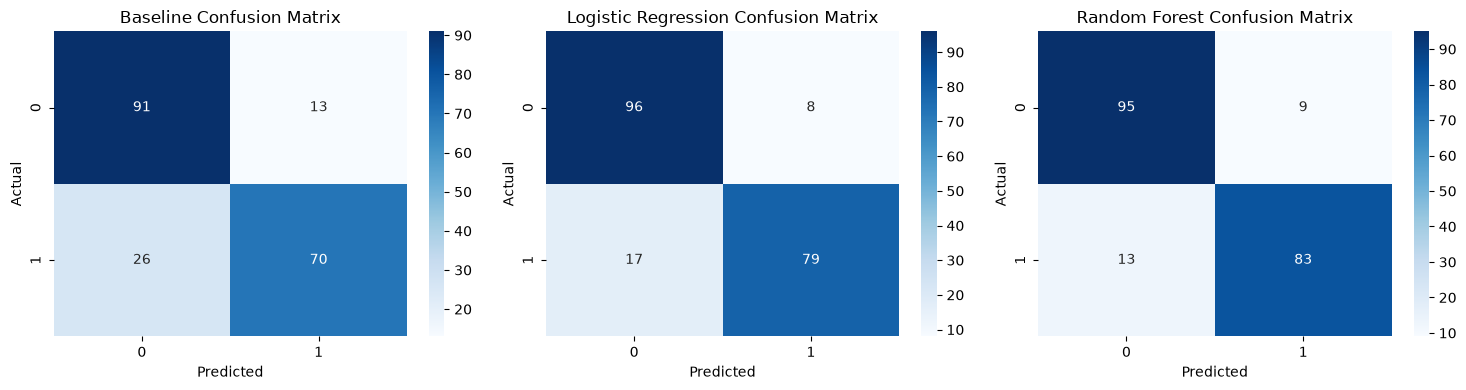

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Baseline
sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Baseline Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# Logistic Regression
sns.heatmap(lr_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Logistic Regression Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

# Random Forest
sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Blues', ax=axes[2])
axes[2].set_title('Random Forest Confusion Matrix')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

## ROC Curve

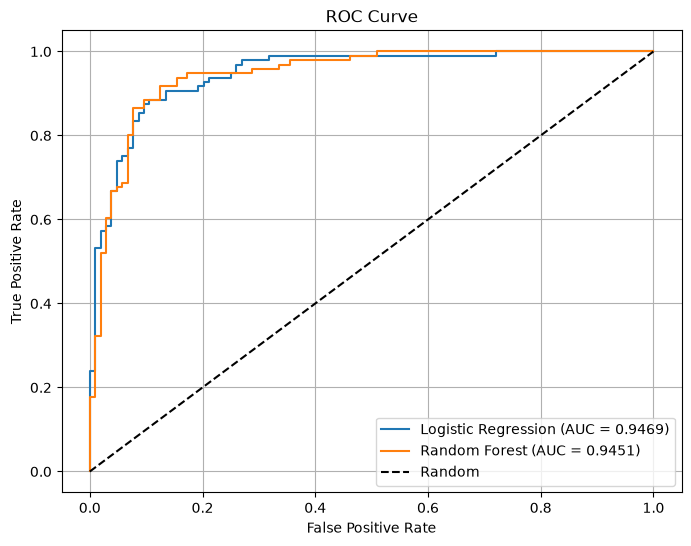

In [11]:
from sklearn.metrics import roc_curve

# Calculate ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

# Plot
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {lr_metrics["roc_auc"]:.4f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {rf_metrics["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

## Feature Importance Comparison

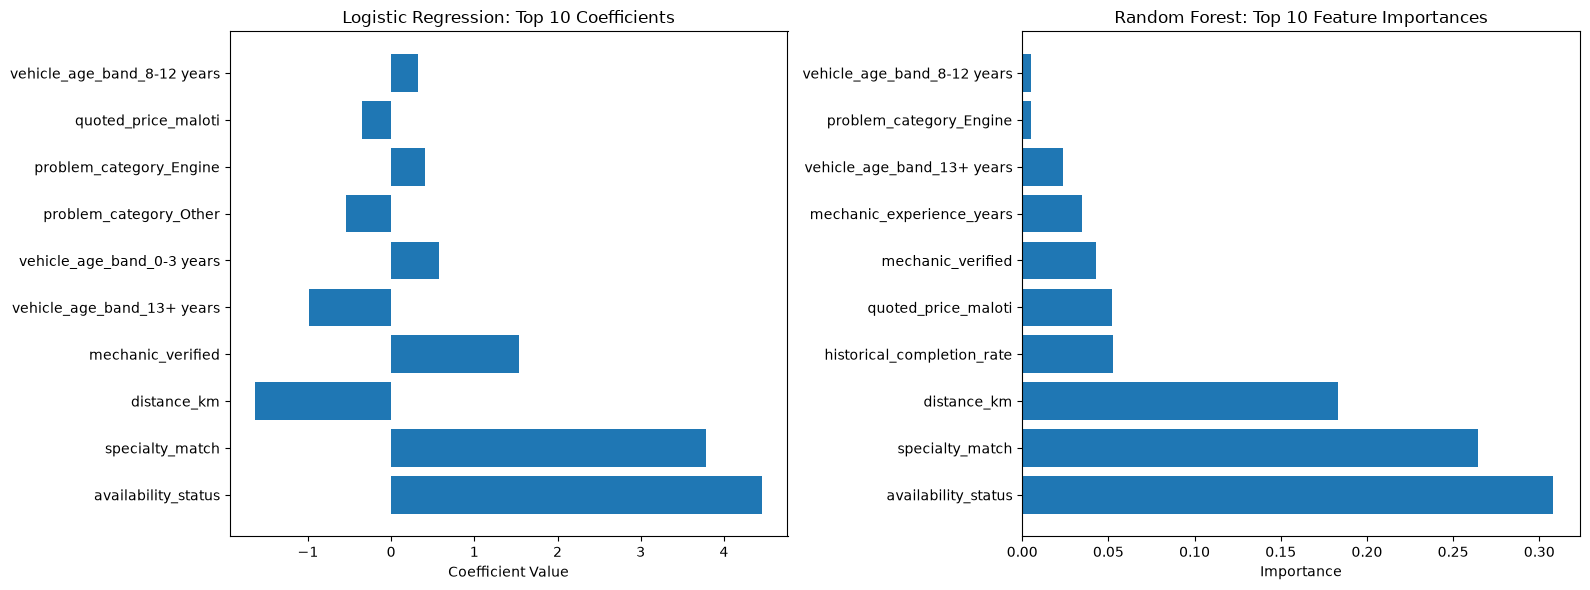

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Logistic Regression coefficients
top_lr = feature_importance.head(10)
axes[0].barh(top_lr['feature'], top_lr['coefficient'])
axes[0].set_title('Logistic Regression: Top 10 Coefficients')
axes[0].set_xlabel('Coefficient Value')

# Random Forest feature importance
top_rf = rf_feature_importance.head(10)
axes[1].barh(top_rf['feature'], top_rf['importance'])
axes[1].set_title('Random Forest: Top 10 Feature Importances')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()

## Summary

This notebook trained three models on the AutoHelp Lesotho dataset:

1. **Baseline (Rule-based)**: Predicts success only when specialty matches AND mechanic is available
2. **Logistic Regression**: Uses gradient descent to learn weights for each feature
3. **Random Forest**: Ensemble of decision trees with bootstrap sampling

The models were evaluated using 80/20 stratified train/test split with 5-fold cross-validation.

Metrics computed: Accuracy, Precision, Recall, F1, ROC-AUC

The TypeScript implementation in the app should produce similar results (within reasonable tolerance due to random seed differences and implementation details).